In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv('powerplant_data.csv')

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
# AT=>temperature 
# V=vaccum 
# AP=pressure
# RH=>humidity

# Pe=produced energy

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X=df.drop('PE',axis=1)
y=df['PE']

In [7]:
#split out data
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [8]:
df.shape

(9568, 5)

In [9]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [10]:
import torch
import torch.nn as nn

In [11]:
X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [12]:
from torch.utils.data import TensorDataset,DataLoader
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

In [13]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

In [14]:
##Deep learning

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        self.model=nn.Sequential(    
            #1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),
    
            #2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),
    
            #output layer
            nn.Linear(6,1)
        )

    def forward(self,x):
        return self.model(x)

In [24]:
import torch.optim as optim
model=ANN()

#loss,optimizer
crietrion=nn.MSELoss()
optimizer=optim.Adam(model.parameters())

In [25]:
#Trian the ANN
train_losses=[]
val_losses=[]
best_val_loss=float('inf')
epochs=100
for epoch in range(epochs):
    model.train()
    running_loss=0.0
    for Xb,yb in train_loader:
        #xb-features of 1 batch
        #yb-labels of 1 batch
        optimizer.zero_grad()

        outputs=model(Xb)#forward propagation ....predicted output for this batch
        loss=crietrion(outputs,yb)#compute loss
        loss.backward()#back prop.. compute gradient
        optimizer.step() #params update

        running_loss+=loss.item() #loss is a tensor=>to convert it py float
    epoch_train_loss= running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)

    #validation
    model.eval()
    running_val_loss=0.0
    with torch.no_grad(): #no gradient compute
        for Xb,yb in test_loader:
            outputs=model(Xb)
            loss=crietrion(outputs,yb)
            running_val_loss+=loss
    epoch_val_loss= running_val_loss/len(test_loader)
    val_losses.append(epoch_val_loss)        
    print(f'epoch ${epoch+1}/{epochs}==>train loss=${epoch_train_loss} & val loss= ${epoch_val_loss}')
    if epoch_val_loss<best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(),'best_model.pt') #.pt or pth
        

epoch $1/100==>train loss=$206460.64069010416 & val loss= $205703.515625
epoch $2/100==>train loss=$203281.9001953125 & val loss= $197173.171875
epoch $3/100==>train loss=$177619.7005859375 & val loss= $149973.828125
epoch $4/100==>train loss=$114919.20319010416 & val loss= $79821.5390625
epoch $5/100==>train loss=$53656.03145345052 & val loss= $33959.33203125
epoch $6/100==>train loss=$25205.379024251302 & val loss= $20037.931640625
epoch $7/100==>train loss=$17293.514884440105 & val loss= $15274.654296875
epoch $8/100==>train loss=$13427.765661621093 & val loss= $11759.3818359375
epoch $9/100==>train loss=$10177.37958984375 & val loss= $8645.9853515625
epoch $10/100==>train loss=$7319.5150695800785 & val loss= $5971.34423828125
epoch $11/100==>train loss=$4909.057529703776 & val loss= $3881.3681640625
epoch $12/100==>train loss=$3136.4143402099608 & val loss= $2433.577880859375
epoch $13/100==>train loss=$1949.4256108601887 & val loss= $1536.006591796875
epoch $14/100==>train loss=$1

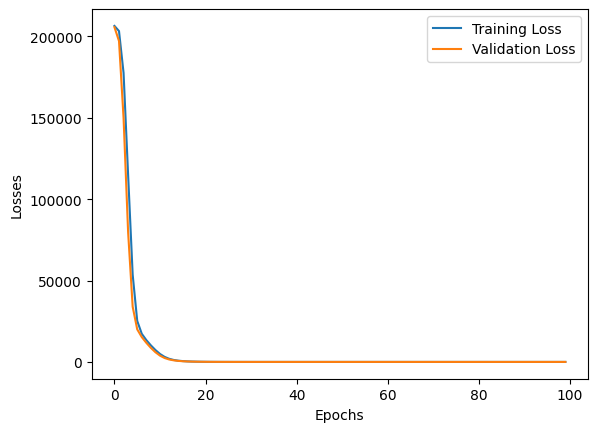

In [26]:
import matplotlib.pyplot as plt
loss_df=pd.DataFrame({
    'Training Loss':train_losses,
    'Validation Loss':val_losses
})

plt.plot(loss_df['Training Loss'],label='Training Loss')
plt.plot(loss_df['Validation Loss'],label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Losses')
plt.legend()

In [27]:
#loding the best model

model.load_state_dict(torch.load('best_model.pt'))

<All keys matched successfully>

In [30]:
#Evaluate  our model
model.eval()
with torch.no_grad():
    train_preds=model(X_train_tensor)
    test_preds=model(X_test_tensor)
    train_mse_loss=crietrion(train_preds,y_train_tensor)
    test_mse_loss=crietrion(test_preds,y_test_tensor)

print('Training MSE:',train_mse_loss.item())
print('Testing MSE:',test_mse_loss.item())

Training MSE: 20.78388786315918
Testing MSE: 18.936433792114258


In [31]:
from sklearn.metrics import r2_score
print('r^2 score=',r2_score(y_test,test_preds))

r^2 score= 0.9338220429589638


In [32]:
predicted_df=pd.DataFrame(test_preds.numpy(),columns=['Predicted Values'])
actual_df=pd.DataFrame(y_test.values,columns=['Actual Values'])
pd.concat([predicted_df,actual_df],axis=1)

,Predicted Values,Actual Values
0,434.851929,433.27
1,436.664246,438.16
2,461.271484,458.42
3,476.251404,480.82
4,435.198486,441.41
...,...,...
1909,451.015686,456.70
1910,431.315186,438.04
1911,467.196167,467.80
1912,430.784912,437.14
